# Promotions

Separate the response to a regular-price change from the response to a temporary discount. `price` stays the price paid. `discount_rate` is the fraction off the regular price (`0.2` = 20% off), and `elasticity_sku` is the regular-price elasticity.

The [promotions guide](../promotions.md) covers the data contract and the identification caveats. Fixed-amount discounts and multibuys have to be converted to an effective percent off the regular price before fitting.

MCMC settings below are small for a fast run. Increase `draws`, `tune`, and `chains` for production-quality inference.


## Data

`promotions=True` writes `discount_rate` and sets `price` to the price paid. Regular price is `price / (1 - discount_rate)`.


In [1]:
%matplotlib inline

from pypricing import (
    LogLogDemandModel,
    PanelColumns,
    apply_discount,
    generate_mock_data,
)

df = generate_mock_data(
    n_periods=40,
    n_skus=4,
    promotions=True,
    promo_frequency=0.4,
    promo_depth=0.2,
    include_seasonality=False,
    random_state=0,
)
shown = df.copy()
shown["regular_price"] = shown["price"] / (1 - shown["discount_rate"])
shown[["sku", "price", "discount_rate", "regular_price", "quantity"]].head(8)


,sku,price,discount_rate,regular_price,quantity
0,sku_1,8.729365,0.0,8.729365,35.799427
1,sku_1,6.854126,0.2,8.567657,74.233340
2,sku_1,8.578286,0.0,8.578286,34.965694
3,sku_1,8.000333,0.0,8.000333,33.577834
4,sku_1,7.947993,0.0,7.947993,28.791909
5,sku_1,7.656402,0.0,7.656402,39.962338
6,sku_1,5.992032,0.2,7.490040,62.143931
7,sku_1,5.894990,0.2,7.368737,77.082403


## Fit

`discount_col` splits the curve. `elasticity_sku` is the regular-price elasticity. `promo_elasticity_sku` is the log-linear promo elasticity. The posterior plot shows them side by side.


In [2]:
model = LogLogDemandModel(
    panel_columns=PanelColumns(discount_col="discount_rate", quantity_floor=1e-6)
)
model.fit(
    df,
    draws=120,
    tune=120,
    chains=2,
    random_seed=0,
    progressbar=False,
    compute_convergence_checks=False,
)

summary = model.fit_summary()
summary.loc[summary.index.str.contains("elasticity")]


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (2 chains in 2 jobs)


NUTS: [alpha_sku, elasticity_sku, sigma, promo_elasticity_sku]


Sampling 2 chains for 120 tune and 120 draw iterations (240 + 240 draws total) took 2 seconds.


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
elasticity_sku[0],-0.336,0.258,-0.834,0.127,0.022,0.014,136.0,151.0,1.00
elasticity_sku[1],-0.869,0.361,-1.482,-0.241,0.034,0.020,113.0,92.0,1.02
elasticity_sku[2],-1.038,0.351,-1.538,-0.309,0.038,0.028,178.0,108.0,1.04
elasticity_sku[3],-0.976,0.231,-1.417,-0.571,0.016,0.017,190.0,115.0,1.01
promo_elasticity_sku[0],-3.344,0.204,-3.688,-2.974,0.011,0.024,365.0,96.0,1.01
promo_elasticity_sku[1],-3.592,0.199,-3.925,-3.223,0.012,0.011,251.0,213.0,1.01
promo_elasticity_sku[2],-3.667,0.181,-4.004,-3.355,0.012,0.015,284.0,166.0,1.00
promo_elasticity_sku[3],-3.437,0.180,-3.737,-3.052,0.013,0.016,209.0,150.0,1.03


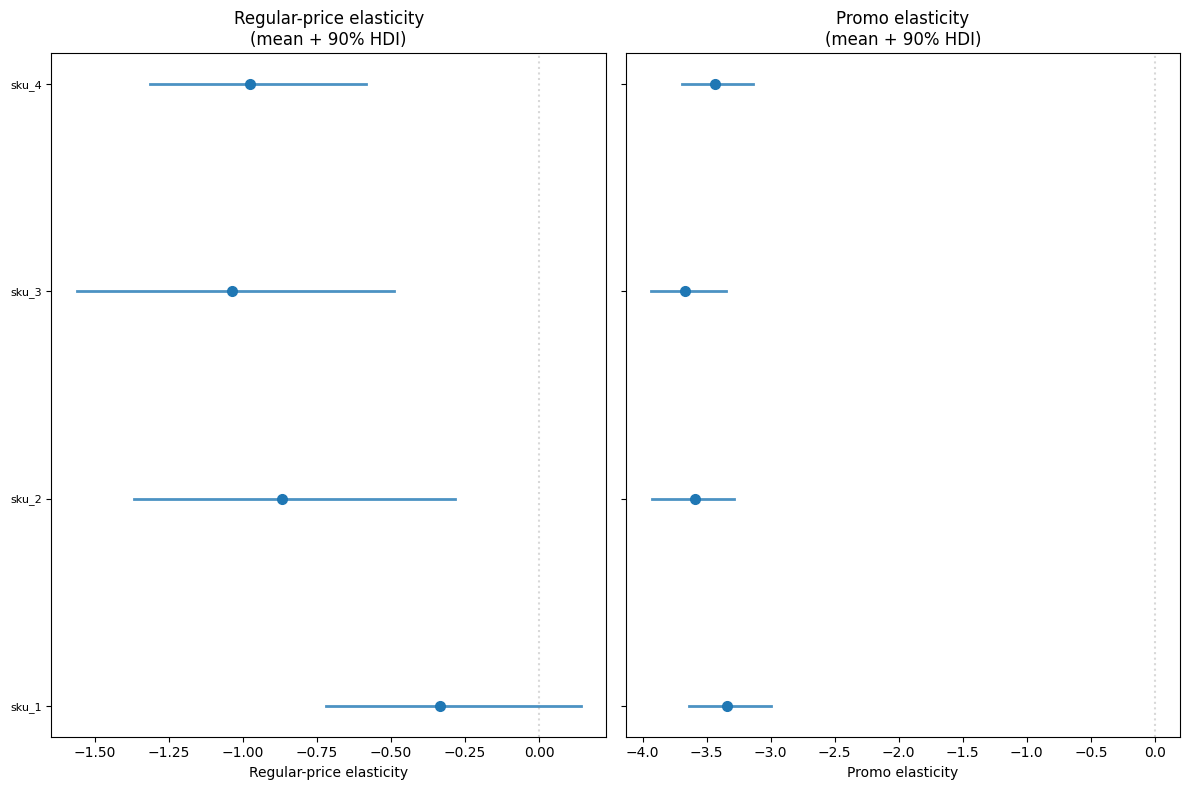

In [3]:
model.plot_elasticity_posterior(hdi_prob=0.9);


## A promo scenario, then the regular price

`apply_discount` sets the discount and scales `price` off the implied regular price, so the two columns stay consistent. `predict` needs the discount column because the model was fit with one.

`optimize_prices` sets the discount to 0 and searches over the regular price. On a log-log curve that optimum sits on a `price_bounds` endpoint.


In [4]:
scenario = apply_discount(df.drop(columns=["quantity"]), 0.2)
model.predict(scenario, hdi_prob=0.9, random_seed=0).head()


,sku,period,price,log_price,log_quantity,discount_rate,quantity_mean,log_quantity_mean,quantity_hdi_lower,quantity_hdi_upper
0,sku_1,0,6.983492,2.166693,3.577932,0.2,71.980099,4.266650,55.140922,88.756984
1,sku_1,1,6.854126,1.924851,4.307213,0.2,72.653307,4.277907,56.099347,84.854167
2,sku_1,2,6.862629,2.149234,3.554367,0.2,71.929920,4.267274,56.016228,86.856951
3,sku_1,3,6.400267,2.079483,3.513866,0.2,72.933362,4.281646,59.358112,89.127646
4,sku_1,4,6.358394,2.072919,3.360094,0.2,74.083307,4.296427,57.359276,88.683924


In [5]:
regular = df["price"] / (1 - df["discount_rate"])
price_bounds = {
    sku: (float(s.min() * 0.8), float(s.max() * 1.2))
    for sku, s in regular.groupby(df["sku"])
}
model.optimize_prices(price_bounds)


/Users/arthur/Library/CloudStorage/GoogleDrive-arthur.bmello@gmail.com/My Drive/1 - Build/1 - Side projects/1 - Ongoing/pypricing/src/pypricing/models/basic.py:1204: UserWarning: 4/4 SKU(s) optimized to a price_bounds edge, not an interior price: {'sku_1': 'high', 'sku_2': 'high', 'sku_3': 'low', 'sku_4': 'high'}. This is expected for log_log demand: revenue is proportional to price^(1+elasticity). Any draw with elasticity other than -1 is monotone in price, and a posterior that straddles -1 is U-shaped, so the constrained optimum is always a price_bounds endpoint. An interior revenue maximum needs a price-dependent elasticity (QuadraticLogDemandModel or SigmoidSaturationDemandModel).
  return _optimize_prices(


,optimal_price,mean_revenue,at_bound
sku,,,
sku_1,11.913257,365.832646,high
sku_2,17.055668,444.165562,high
sku_3,1.542019,186.007717,low
sku_4,8.250550,194.388895,high
